In [1]:
import os, shutil, sys

problemas = []
if not os.path.isdir("/opt/spark"):
    problemas.append("no existe /opt/spark: no estás en el contenedor del clúster")
if shutil.which("java") is None:
    problemas.append("no hay Java en el PATH: PySpark no puede arrancar la JVM")
try:
    import pyspark
    if not pyspark.__file__.startswith("/opt/spark/"):
        problemas.append(f"pyspark viene de {pyspark.__file__} en vez de /opt/spark/python")
except ImportError:
    problemas.append("pyspark no es importable")

if problemas:
    print("ESTE NOTEBOOK NO ESTÁ CORRIENDO EN EL CLÚSTER")
    for p in problemas:
        print(f"  - {p}")
    print("  Ábrelo en http://localhost:8889 (token: lab-sitio3)")
    raise SystemExit("Entorno incorrecto: usa http://localhost:8889")

print("Entorno correcto")
print(f"  Python  : {sys.version.split()[0]}")
print(f"  Java    : {shutil.which('java')}")
print(f"  PySpark : {pyspark.__file__}")

Entorno correcto
  Python  : 3.10.12
  Java    : /opt/java/openjdk/bin/java
  PySpark : /opt/spark/python/pyspark/__init__.py


In [2]:
import os, time, json, re, statistics, uuid
from urllib.request import urlopen
from urllib.error import HTTPError
import pandas as pd
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import (StructType, StructField, StringType,
                               DoubleType, LongType, TimestampType, DateType)

spark = (
    SparkSession.builder
    .appName("fase2-sitio3")
    .master(os.environ.get("SPARK_MASTER_URL", "spark://spark-master:7077"))
    .config("spark.driver.host", os.environ.get("SPARK_DRIVER_HOST", "jupyter"))
    .config("spark.driver.bindAddress", "0.0.0.0")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
    .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
    .config("spark.ui.showConsoleProgress", "false")   # sin barras de progreso en las salidas
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext

# Los executors tardan unos segundos en registrarse. Se espera uno por cada worker vivo
# del master (lo mismo que muestra la UI :8080), no solo el primero que aparezca.
esperados = json.load(urlopen("http://spark-master:8080/json/"))["aliveworkers"]
for _ in range(60):
    n_exec = sc._jsc.sc().getExecutorMemoryStatus().size() - 1   # incluye al driver: -1
    if n_exec >= esperados:
        break
    time.sleep(1)
assert n_exec > 0, "0 executors: revisa que SPARK_EXECUTOR_MEMORY <= SPARK_WORKER_MEMORY en .env"
assert n_exec >= esperados, f"Solo {n_exec} de {esperados} executors se registraron en 60 s"

CORES = sc.defaultParallelism
print(f"Spark          : {spark.version}")
print(f"Master         : {sc.master}")
print(f"Executors      : {n_exec}  (workers vivos en el master: {esperados})")
print(f"Paralelismo    : {CORES} tareas simultáneas")
print(f"UI del driver  : http://localhost:4040  (dentro del contenedor: {sc.uiWebUrl})")

M = {}   # aquí se van guardando todas las mediciones del notebook

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/24 21:03:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark          : 4.0.1
Master         : spark://spark-master:7077
Executors      : 2  (workers vivos en el master: 2)
Paralelismo    : 4 tareas simultáneas
UI del driver  : http://localhost:4040  (dentro del contenedor: http://jupyter:4040)


In [3]:
def a_gb(txt):
    txt = txt.strip().lower()
    return float(txt[:-1]) / (1024 if txt.endswith("m") else 1)

with open("/proc/meminfo") as f:
    ram_docker_gb = int(f.readline().split()[1]) / 1024**2

# Workers y su memoria se leen del master (lo mismo que muestra la UI :8080), es decir,
# SPARK_WORKERS y SPARK_WORKER_MEMORY tal como quedaron aplicados, no un valor escrito a mano.
estado    = json.load(urlopen("http://spark-master:8080/json/"))
vivos     = [w for w in estado["workers"] if w["state"] == "ALIVE"]
workers   = len(vivos)
w_mem     = max(w["memory"] for w in vivos) / 1024          # MB -> GB (SPARK_WORKER_MEMORY)
w_cores   = max(w["cores"] for w in vivos)
drv_mem   = a_gb(os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
reservado = sum(w["memory"] for w in vivos) / 1024 + drv_mem
exec_mem  = a_gb(os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
assert exec_mem <= w_mem, "SPARK_EXECUTOR_MEMORY no cabe en SPARK_WORKER_MEMORY: no habría executors"

print(f"RAM asignada a Docker        : {ram_docker_gb:.1f} GB  ({os.cpu_count()} CPUs)")
print(f"Workers x memoria + driver   : {workers} x {w_mem:g} GB + {drv_mem:g} GB = {reservado:g} GB")
print(f"Margen para el SO y Jupyter  : {ram_docker_gb - reservado:.1f} GB")
print(f"Perfil aplicado              : {workers} workers x {w_cores} cores x {w_mem:g} GB, driver {drv_mem:g} GB")
if ram_docker_gb >= 12:
    # Con 16 GB la guía sugiere 3 workers x 3g; se mantiene el de 8 GB a propósito:
    # todas las mediciones del notebook se hicieron con 4 cores, y el margen libre
    # queda para Docker Desktop, el navegador y la UI de Spark.
    print(f"Nota: Docker tiene {ram_docker_gb:.0f} GB; se usa el perfil de 8 GB de forma conservadora "
          f"(margen de {ram_docker_gb - reservado:.0f} GB) para que las mediciones sean comparables.")
assert reservado < ram_docker_gb, "El clúster pide más memoria de la que tiene Docker"
M["ram_docker_gb"] = round(ram_docker_gb, 1)

RAM asignada a Docker        : 15.5 GB  (8 CPUs)
Workers x memoria + driver   : 2 x 2 GB + 2 GB = 6 GB
Margen para el SO y Jupyter  : 9.5 GB
Perfil aplicado              : 2 workers x 2 cores x 2 GB, driver 2 GB
Nota: Docker tiene 16 GB; se usa el perfil de 8 GB de forma conservadora (margen de 10 GB) para que las mediciones sean comparables.


In [4]:
def medir(df, reps=3):
    """Mediana (s) de ejecutar la consulta entera sin traer filas al driver."""
    tiempos = []
    for _ in range(reps):
        t0 = time.perf_counter()
        df.write.format("noop").mode("overwrite").save()
        tiempos.append(time.perf_counter() - t0)
    return round(statistics.median(tiempos), 2)


def plan_fisico(df):
    """Plan físico hasta la tabla cacheada: lo que hay debajo de InMemoryRelation es el plan
    de la limpieza (ya ejecutado y guardado en memoria), no el de esta consulta."""
    plan = df._jdf.queryExecution().executedPlan().toString()
    salida, nivel_oculto = [], None
    for linea in plan.splitlines():
        nivel = next((i for i, ch in enumerate(linea) if ch.isalnum()), len(linea))
        if nivel_oculto is not None and nivel > nivel_oculto:
            continue                      # rama interna de la tabla cacheada: se omite
        nivel_oculto = None
        salida.append(linea)
        if "InMemoryRelation" in linea:
            nivel_oculto = nivel
    return "\n".join(salida)


def mostrar_plan(df):
    for linea in plan_fisico(df).splitlines():
        if linea.strip(" :+-"):
            print(linea)


def contar_exchanges(df):
    plan = plan_fisico(df)
    shuffles   = len(re.findall(r"(?<!Broadcast)Exchange (hashpartitioning|rangepartitioning|RoundRobinPartitioning|SinglePartition)", plan))
    broadcasts = len(re.findall(r"BroadcastExchange", plan))
    return shuffles, broadcasts


ultima_etiqueta = {}   # grupo -> etiqueta de su última ejecución


def ejecutar_en_grupo(grupo, df):
    """Ejecuta df etiquetando sus jobs, para poder buscarlos después en la UI. Cada ejecución
    tiene una etiqueta única (grupo#uuid): repetir una celda, o esta misma, no mezcla corridas."""
    ultima_etiqueta[grupo] = f"{grupo}#{uuid.uuid4().hex}"
    sc.setJobGroup(ultima_etiqueta[grupo], grupo)
    try:
        t0 = time.perf_counter()
        df.write.format("noop").mode("overwrite").save()
        dur = time.perf_counter() - t0
    finally:
        sc.setJobGroup("otros", "otros")
    time.sleep(2)            # la UI registra las métricas de forma asíncrona
    return round(dur, 2)


def tareas(grupo):
    """Duración y filas leídas del shuffle de cada tarea de la última ejecución del grupo."""
    base = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
    jobs = sc.statusTracker().getJobIdsForGroup(ultima_etiqueta[grupo])
    # Con AQE, varios jobs de la misma consulta comparten etapas: cada etapa se cuenta una vez.
    etapas = sorted({sid for jid in jobs for sid in sc.statusTracker().getJobInfo(jid).stageIds})
    por_tarea = {}
    for sid in etapas:
        try:
            intentos = json.load(urlopen(f"{base}/stages/{sid}?details=false"))
        except HTTPError as e:
            if e.code == 404:
                continue     # etapa saltada: nunca se ejecutó
            raise
        for intento in sorted(intentos, key=lambda a: a["attemptId"]):
            url = f"{base}/stages/{sid}/{intento['attemptId']}/taskList?length=100000"
            for t in json.load(urlopen(url)):
                if t.get("status") == "SUCCESS":
                    por_tarea[(sid, t["index"])] = t   # si se reintentó, queda el último intento
    filas = []
    for (sid, _), t in sorted(por_tarea.items()):
        m = t.get("taskMetrics") or {}
        filas.append(dict(etapa=sid,
                          dur_ms=m.get("executorRunTime", 0),
                          filas_shuffle=(m.get("shuffleReadMetrics") or {}).get("recordsRead", 0)))
    return pd.DataFrame(filas)


def resumen_etapa_shuffle(grupo):
    """De las etapas que LEEN un shuffle, la de mayor volumen: nº de tareas, mediana y máximo."""
    t = tareas(grupo)
    t = t[t.filas_shuffle > 0]
    etapa = t.groupby("etapa").filas_shuffle.sum().idxmax()
    e = t[t.etapa == etapa]
    med = max(e.dur_ms.median(), 1)
    return dict(etapa=int(etapa), tareas_con_shuffle=len(e),
                mediana_ms=int(e.dur_ms.median()), max_ms=int(e.dur_ms.max()),
                ratio_max_mediana=round(e.dur_ms.max() / med, 1),
                max_filas=int(e.filas_shuffle.max()),
                mediana_filas=int(e.filas_shuffle.median())), e

print("Herramientas listas")

Herramientas listas


In [5]:
RAW = "/opt/workspace/data/raw/*.jsonl"

esquema_raw = StructType([
    StructField("timestamp",  TimestampType(), True),   # ISO 8601 con "Z": Spark lo convierte solo
    StructField("sensor_id",  StringType(), True),
    StructField("metric",     StringType(), True),
    StructField("value",      DoubleType(), True),
    StructField("unit",       StringType(), True),
    StructField("worker_id",  LongType(),   True),
    StructField("site",       StringType(), True),
    StructField("asset_type", StringType(), True),
    StructField("status",     StringType(), True),
    StructField("seq",        LongType(),   True),
])

# (a) Inferido: el propio spark.read.json ya lanza un job que lee TODO para adivinar tipos.
t0 = time.perf_counter()
df_inferido = spark.read.json(RAW)
t_inferencia = time.perf_counter() - t0
t0 = time.perf_counter()
n_inf = df_inferido.count()
t_conteo_inf = time.perf_counter() - t0

# (b) Declarado: leer no cuesta nada (evaluación perezosa); solo el count ejecuta.
t0 = time.perf_counter()
raw = spark.read.schema(esquema_raw).json(RAW)
t_decl_lectura = time.perf_counter() - t0
t0 = time.perf_counter()
n_raw = raw.count()
t_conteo_decl = time.perf_counter() - t0

assert n_inf == n_raw
print(pd.DataFrame([
    ["inferido",  round(t_inferencia, 2),  round(t_conteo_inf, 2),  round(t_inferencia + t_conteo_inf, 2)],
    ["declarado", round(t_decl_lectura, 2), round(t_conteo_decl, 2), round(t_decl_lectura + t_conteo_decl, 2)],
], columns=["esquema", "spark.read (s)", "count (s)", "total (s)"]).to_string(index=False))
print(f"\nRegistros: {n_raw:,}")
print(f"Ahorro por declarar el esquema: {t_inferencia + t_conteo_inf - t_decl_lectura - t_conteo_decl:.1f} s "
      f"({(t_inferencia + t_conteo_inf) / (t_decl_lectura + t_conteo_decl):.1f}x)")
M.update(raw_registros=n_raw, t_inferido=round(t_inferencia + t_conteo_inf, 2),
         t_declarado=round(t_decl_lectura + t_conteo_decl, 2))

  esquema  spark.read (s)  count (s)  total (s)
 inferido           42.27      20.75      63.02
declarado            0.25      15.67      15.92

Registros: 10,000,014
Ahorro por declarar el esquema: 47.1 s (4.0x)


In [6]:
# ¿Qué tipos adivinó Spark? La inferencia deja timestamp como texto (string); el esquema
# declarado lo tipa como timestamp. Y no hay garantía de estabilidad: un archivo con un
# "value": "NaN" como texto cambiaría la columna entera a string.
print("Inferido :", [(f.name, f.dataType.simpleString()) for f in df_inferido.schema.fields])
print("Declarado:", [(f.name, f.dataType.simpleString()) for f in raw.schema.fields])

Inferido : [('asset_type', 'string'), ('metric', 'string'), ('sensor_id', 'string'), ('seq', 'bigint'), ('site', 'string'), ('status', 'string'), ('timestamp', 'string'), ('unit', 'string'), ('value', 'double'), ('worker_id', 'bigint')]
Declarado: [('timestamp', 'timestamp'), ('sensor_id', 'string'), ('metric', 'string'), ('value', 'double'), ('unit', 'string'), ('worker_id', 'bigint'), ('site', 'string'), ('asset_type', 'string'), ('status', 'string'), ('seq', 'bigint')]


In [7]:
t0 = time.perf_counter()
alarmas = (raw.filter(F.col("status") == "ALARM")
              .withColumn("value_f", F.col("value") * 9 / 5 + 32)
              .select("timestamp", "sensor_id", "value_f"))
t_transf = time.perf_counter() - t0

alarmas.explain()

t0 = time.perf_counter()
n_alarmas = alarmas.count()
t_accion = time.perf_counter() - t0

print(f"\nTransformaciones (filter, withColumn, select): {t_transf:.3f} s")
print(f"Acción (count)                               : {t_accion:.2f} s  ->  {n_alarmas:,} alarmas")
M.update(t_lazy_transf=round(t_transf, 3), t_lazy_accion=round(t_accion, 2))


== Physical Plan ==
*(1) Project [timestamp#30, sensor_id#31, (((value#33 * 9.0) / 5.0) + 32.0) AS value_f#55]
+- *(1) Filter (isnotnull(status#38) AND (status#38 = ALARM))
   +- FileScan json [timestamp#30,sensor_id#31,value#33,status#38] Batched: false, DataFilters: [isnotnull(status#38), (status#38 = ALARM)], Format: JSON, Location: InMemoryFileIndex(4 paths)[file:/opt/workspace/data/raw/part-000.jsonl, file:/opt/workspace/data/..., PartitionFilters: [], PushedFilters: [IsNotNull(status), EqualTo(status,ALARM)], ReadSchema: struct<timestamp:timestamp,sensor_id:string,value:double,status:string>





Transformaciones (filter, withColumn, select): 0.126 s
Acción (count)                               : 16.87 s  ->  2,198 alarmas


In [8]:
import glob, math
bytes_raw = sum(os.path.getsize(p) for p in glob.glob(RAW))
max_part = 128 * 1024**2
bloques = [math.ceil(os.path.getsize(p) / max_part) for p in sorted(glob.glob(RAW))]
print(f"Tamaño del crudo        : {bytes_raw / 1024**3:.2f} GB en {len(glob.glob(RAW))} archivos")
print(f"maxPartitionBytes       : {spark.conf.get('spark.sql.files.maxPartitionBytes')}")
print(f"Total / 128 MB          : {bytes_raw / max_part:.1f}  (solo referencia)")
print(f"Bloques por archivo     : {bloques}  -> {sum(bloques)} trozos antes de agruparlos")
print(f"Particiones reales      : {raw.rdd.getNumPartitions()}")
print(f"Cores del clúster       : {CORES}  -> {raw.rdd.getNumPartitions() / CORES:.1f} 'olas' de tareas")
M["raw_particiones"] = raw.rdd.getNumPartitions()

Tamaño del crudo        : 1.75 GB en 4 archivos
maxPartitionBytes       : 134217728b
Total / 128 MB          : 14.0  (solo referencia)
Bloques por archivo     : [4, 4, 4, 4]  -> 16 trozos antes de agruparlos
Particiones reales      : 15
Cores del clúster       : 4  -> 3.8 'olas' de tareas


In [9]:
BRONZE = "/opt/workspace/salida_fase2/bronze_raw.parquet"
t0 = time.perf_counter()
raw.write.mode("overwrite").parquet(BRONZE)
t_escritura = time.perf_counter() - t0

bronze = spark.read.parquet(BRONZE)
bytes_bronze = sum(os.path.getsize(p) for p in glob.glob(f"{BRONZE}/*.parquet"))

consulta_json    = raw.groupBy("metric").agg(F.avg("value"))
consulta_parquet = bronze.groupBy("metric").agg(F.avg("value"))
t_json, t_parquet = medir(consulta_json, 1), medir(consulta_parquet, 2)   # JSON: 1 pasada, cada una lee 1,8 GB

print(f"Conversión JSON -> Parquet : {t_escritura:.1f} s (se paga una vez)")
print(f"Tamaño JSON / Parquet      : {bytes_raw/1024**2:,.0f} MB / {bytes_bronze/1024**2:,.0f} MB "
      f"({bytes_raw/bytes_bronze:.1f}x más chico)")
print(f"Promedio por métrica       : JSON {t_json} s  vs  Parquet {t_parquet} s "
      f"({t_json/t_parquet:.1f}x más rápido)")
M.update(mb_json=round(bytes_raw/1024**2), mb_parquet=round(bytes_bronze/1024**2),
         t_consulta_json=t_json, t_consulta_parquet=t_parquet)

Conversión JSON -> Parquet : 59.4 s (se paga una vez)
Tamaño JSON / Parquet      : 1,791 MB / 22 MB (81.4x más chico)
Promedio por métrica       : JSON 22.24 s  vs  Parquet 1.71 s (13.0x más rápido)


In [10]:
n = bronze.count()
nulos = bronze.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in bronze.columns]).toPandas()
print("Nulos por columna:")
print(nulos.to_string(index=False))
# Un timestamp que no calce con el formato no da error: queda nulo. Esta aserción lo detecta.
assert int(nulos["timestamp"][0]) == 0, "Hay timestamps que no se pudieron convertir"

dup_exactos = n - bronze.dropDuplicates().count()
dup_clave   = n - bronze.dropDuplicates(["timestamp", "sensor_id", "metric"]).count()
print(f"\nDuplicados exactos                        : {dup_exactos:,}")
print(f"Duplicados por (timestamp, sensor, métrica): {dup_clave:,}")
M.update(raw_nulos=int(nulos.sum(axis=1)[0]), raw_dup_exactos=dup_exactos, raw_dup_clave=dup_clave)

Nulos por columna:
 timestamp  sensor_id  metric  value  unit  worker_id  site  asset_type  status  seq
         0          0       0      0     0          0     0           0       0    0



Duplicados exactos                        : 0
Duplicados por (timestamp, sensor, métrica): 0


In [11]:
print("Métricas, unidades y rangos:")
bronze.groupBy("metric", "unit").agg(
    F.count("*").alias("registros"),
    F.round(F.min("value"), 2).alias("min"),
    F.round(F.max("value"), 2).alias("max"),
    F.round(F.avg("value"), 2).alias("media"),
).orderBy("metric").show()

print("Tipo de activo y estado:")
bronze.groupBy("asset_type").agg(
    F.countDistinct("sensor_id").alias("sensores"),
    F.count("*").alias("registros"),
    F.sum((F.col("status") == "ALARM").cast("int")).alias("alarmas"),
).orderBy(F.desc("registros")).show()

rango = bronze.agg(F.min("timestamp").alias("desde"), F.max("timestamp").alias("hasta"),
                   F.countDistinct("sensor_id").alias("sensores")).first()
print(f"Rango temporal: {rango.desde} -> {rango.hasta} | sensores distintos: {rango.sensores}")

Métricas, unidades y rangos:


+-----------+----+---------+------+-------+-------+
|     metric|unit|registros|   min|    max|  media|
+-----------+----+---------+------+-------+-------+
|    current|   A|  3128496|  0.89|   74.1|  14.24|
|   humidity|   %|  2681568| 78.52|  96.67|  82.01|
|temperature|   C|  3351960|-18.45|  22.53|  -11.5|
|  vibration|mm/s|   335196|  0.38|   5.97|   2.23|
|     weight|  kg|   502794|   0.0|42002.9|4819.08|
+-----------+----+---------+------+-------+-------+

Tipo de activo y estado:


+-----------+--------+---------+-------+
| asset_type|sensores|registros|alarmas|
+-----------+--------+---------+-------+
|     reefer|      48|  8044704|   2198|
|   conveyor|       6|  1005588|      0|
|       yard|      12|   670392|      0|
|      crane|       2|   223464|      0|
|weighbridge|       1|    55866|      0|
+-----------+--------+---------+-------+



Rango temporal: 2026-08-24 00:00:00 -> 2026-09-02 16:46:15 | sensores distintos: 69


In [12]:
bronze.filter("status = 'ALARM'").groupBy("asset_type", "metric").agg(
    F.count("*").alias("alarmas"),
    F.round(F.min("value"), 2).alias("min"), F.round(F.max("value"), 2).alias("max"),
).orderBy(F.desc("alarmas")).show()

+----------+-----------+-------+-----+-----+
|asset_type|     metric|alarmas|  min|  max|
+----------+-----------+-------+-----+-----+
|    reefer|temperature|   2198|-15.0|-8.51|
+----------+-----------+-------+-----+-----+



In [13]:
print("Filas por bandera de calidad (status):")
bronze.groupBy("status").count().orderBy(F.desc("count")).show()

print("WARN por tipo de activo y métrica:")
bronze.filter("status = 'WARN'").groupBy("asset_type", "metric").count().orderBy(F.desc("count")).show()

print("Filas por sensor (los 3 con más y los 3 con menos lecturas):")
por_sensor = bronze.groupBy("asset_type", "sensor_id").count()
por_sensor.orderBy(F.desc("count"), "sensor_id").show(3)
por_sensor.orderBy("count", "sensor_id").show(3)

M.update(raw_warn=bronze.filter("status = 'WARN'").count(),
         raw_alarm=bronze.filter("status = 'ALARM'").count())

Filas por bandera de calidad (status):


+------+-------+
|status|  count|
+------+-------+
|    OK|9992911|
|  WARN|   4905|
| ALARM|   2198|
+------+-------+

WARN por tipo de activo y métrica:


+-----------+-----------+-----+
| asset_type|     metric|count|
+-----------+-----------+-----+
|     reefer|temperature| 1876|
|      crane|    current| 1360|
|   conveyor|  vibration|  968|
|weighbridge|     weight|  505|
|   conveyor|    current|  196|
+-----------+-----------+-----+

Filas por sensor (los 3 con más y los 3 con menos lecturas):


+----------+----------+------+
|asset_type| sensor_id| count|
+----------+----------+------+
|  conveyor|FAJA_S3_C1|167598|
|  conveyor|FAJA_S3_C2|167598|
|  conveyor|FAJA_S3_C3|167598|
+----------+----------+------+
only showing top 3 rows


+----------+--------------+-----+
|asset_type|     sensor_id|count|
+----------+--------------+-----+
|      yard|AMBIENTE_S3_01|55866|
|      yard|AMBIENTE_S3_02|55866|
|      yard|AMBIENTE_S3_03|55866|
+----------+--------------+-----+
only showing top 3 rows


In [14]:
TELE   = "/opt/workspace/salida_sitio3/telemetria.parquet"
VERDAD = "/opt/workspace/salida_sitio3/verdad_terreno.parquet"

tele   = spark.read.parquet(TELE)
verdad = spark.read.parquet(VERDAD)
n_tele = tele.count()

tele.printSchema()
print(f"Filas de telemetría : {n_tele:,}")
print(f"Carpetas (días)     : {sorted(os.listdir(TELE))}")
verdad.orderBy("t_inicio").show(truncate=False)
M["tele_filas"] = n_tele

root
 |-- timestamp_utc: timestamp (nullable = true)
 |-- entidad_id: string (nullable = true)
 |-- entidad_tipo: string (nullable = true)
 |-- alimentador_id: short (nullable = true)
 |-- variable: string (nullable = true)
 |-- valor: double (nullable = true)
 |-- unidad: string (nullable = true)
 |-- calidad_sensor: string (nullable = true)
 |-- fecha: date (nullable = true)

Filas de telemetría : 6,395,325
Carpetas (días)     : ['fecha=2026-01-12', 'fecha=2026-01-13', 'fecha=2026-01-14', 'fecha=2026-01-15', 'fecha=2026-01-16', 'fecha=2026-01-17', 'fecha=2026-01-18']


+--------+-----------------------+----------------+--------------------+--------------------------+--------------------------+-------------------+-------------------+---------+
|falla_id|tipo_falla             |entidad_afectada|alimentador_afectado|t_inicio                  |t_fin                     |parametro_alterado |magnitud           |severidad|
+--------+-----------------------+----------------+--------------------+--------------------------+--------------------------+-------------------+-------------------+---------+
|F006    |rodamiento_faja        |faja_1          |NULL                |2026-01-12 21:37:24.302669|2026-01-13 20:40:30.591189|friccion_factor    |0.8531670517070482 |severa   |
|F001    |compresor_degradado    |reefer_51       |NULL                |2026-01-13 13:34:57.285752|2026-01-14 00:35:06.906476|cop_factor         |0.441877952528782  |moderada |
|F004    |apertura_alimentador   |alimentador_2   |2.0                 |2026-01-14 07:27:00.678696|2026-01-14 08:40

In [15]:
un_dia = tele.filter(F.col("fecha") == F.lit("2026-01-14").cast("date"))
plan = plan_fisico(un_dia)
print(re.search(r"PartitionFilters: \[.*?\]", plan).group(0))
t_todo, t_dia = medir(tele), medir(un_dia)
print(f"Leer los 7 días : {t_todo} s")
print(f"Leer 1 día      : {t_dia} s  (Spark ignora las otras 6 carpetas)")
M.update(t_pruning_todo=t_todo, t_pruning_dia=t_dia)

PartitionFilters: [isnotnull(fecha#564), (fecha#564 = 2026-01-14)]


Leer los 7 días : 1.41 s
Leer 1 día      : 0.37 s  (Spark ignora las otras 6 carpetas)


In [16]:
print("Nulos por columna:")
tele.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in tele.columns]).show()

print("¿De quién son los nulos de alimentador_id?")
tele.groupBy("entidad_tipo").agg(
    F.count("*").alias("filas"),
    F.sum(F.col("alimentador_id").isNull().cast("int")).alias("alimentador_id_nulo"),
).orderBy("entidad_tipo").show()

Nulos por columna:


+-------------+----------+------------+--------------+--------+-----+------+--------------+-----+
|timestamp_utc|entidad_id|entidad_tipo|alimentador_id|variable|valor|unidad|calidad_sensor|fecha|
+-------------+----------+------------+--------------+--------+-----+------+--------------+-----+
|            0|         0|           0|       3290685|       0|    0|     0|             0|    0|
+-------------+----------+------------+--------------+--------+-----+------+--------------+-----+

¿De quién son los nulos de alimentador_id?


+------------+-------+-------------------+
|entidad_tipo|  filas|alimentador_id_nulo|
+------------+-------+-------------------+
| alimentador|  80640|                  0|
|    ambiente|  50400|              50400|
|     bascula| 136092|             136092|
|       buque|  10085|              10085|
|        faja|3024000|            3024000|
|        grua|  60023|              60023|
|   operacion|  10085|              10085|
|      reefer|3024000|                  0|
+------------+-------+-------------------+



In [17]:
print("Calidad de sensor (la marca el propio simulador):")
tele.groupBy("calidad_sensor").count().orderBy(F.desc("count")).show()

dup_exactos_tele = n_tele - tele.dropDuplicates().count()
print(f"Duplicados exactos: {dup_exactos_tele}")
tele.groupBy(tele.columns).count().filter("count > 1").show(truncate=False)

Calidad de sensor (la marca el propio simulador):


+--------------+-------+
|calidad_sensor|  count|
+--------------+-------+
|            ok|6271106|
|  asentamiento| 123241|
|        deriva|    607|
|        pegado|    371|
+--------------+-------+



Duplicados exactos: 2


+-------------------+----------+------------+--------------+-----------------+-----+------+--------------+----------+-----+
|timestamp_utc      |entidad_id|entidad_tipo|alimentador_id|variable         |valor|unidad|calidad_sensor|fecha     |count|
+-------------------+----------+------------+--------------+-----------------+-----+------+--------------+----------+-----+
|2026-01-12 00:00:00|buque_1   |buque       |NULL          |nave_en_sitio    |0.0  |bool  |ok            |2026-01-12|2    |
|2026-01-12 00:00:00|sitio_3   |operacion   |NULL          |suspension_viento|0.0  |bool  |ok            |2026-01-12|2    |
+-------------------+----------+------------+--------------+-----------------+-----+------+--------------+----------+-----+



In [18]:
clave = ["timestamp_utc", "entidad_id", "variable"]
dup_clave_tele = n_tele - tele.dropDuplicates(clave).count()
print(f"Filas repetidas por (timestamp, entidad, variable): {dup_clave_tele:,}")
(tele.groupBy(clave).count().filter("count > 1")
     .groupBy("entidad_id", "variable").agg(F.count("*").alias("claves_repetidas"),
                                            F.max("count").alias("max_filas_por_clave"))
     .show())
print("Ejemplo: 11 lecturas de la báscula en el mismo segundo, todas con valor distinto")
(tele.filter("entidad_id = 'bascula_1' AND variable = 'peso_bruto_kg'")
     .orderBy("timestamp_utc").select("timestamp_utc", "valor", "calidad_sensor").show(12, truncate=False))
M.update(tele_dup_exactos=dup_exactos_tele, tele_dup_clave=dup_clave_tele)

Filas repetidas por (timestamp, entidad, variable): 109,982


+----------+-----------------+----------------+-------------------+
|entidad_id|         variable|claves_repetidas|max_filas_por_clave|
+----------+-----------------+----------------+-------------------+
|   buque_1|    nave_en_sitio|               1|                  2|
| bascula_1|    peso_bruto_kg|           13002|                 11|
|   sitio_3|suspension_viento|               1|                  2|
+----------+-----------------+----------------+-------------------+

Ejemplo: 11 lecturas de la báscula en el mismo segundo, todas con valor distinto


+-------------------+------------------+--------------+
|timestamp_utc      |valor             |calidad_sensor|
+-------------------+------------------+--------------+
|2026-01-12 05:21:36|48099.924368304426|asentamiento  |
|2026-01-12 05:21:36|47639.55393168593 |asentamiento  |
|2026-01-12 05:21:36|46906.98717823912 |asentamiento  |
|2026-01-12 05:21:36|46023.10775340291 |asentamiento  |
|2026-01-12 05:21:36|45107.44404533175 |asentamiento  |
|2026-01-12 05:21:36|44265.24799114416 |asentamiento  |
|2026-01-12 05:21:36|43578.061772516696|asentamiento  |
|2026-01-12 05:21:36|43098.289634438785|asentamiento  |
|2026-01-12 05:21:36|42847.77547321498 |asentamiento  |
|2026-01-12 05:21:36|42819.94696347258 |asentamiento  |
|2026-01-12 05:21:36|42984.7607196904  |asentamiento  |
|2026-01-12 05:21:37|43696.330839828355|asentamiento  |
+-------------------+------------------+--------------+
only showing top 12 rows


In [19]:
print("Rangos por variable (¿hay algo físicamente imposible?):")
tele.groupBy("variable", "unidad").agg(
    F.count("*").alias("filas"),
    F.round(F.min("valor"), 2).alias("min"), F.round(F.max("valor"), 2).alias("max"),
).orderBy("variable").show(30, truncate=False)

Rangos por variable (¿hay algo físicamente imposible?):


+---------------------+-----------+-------+--------+-------+
|variable             |unidad     |filas  |min     |max    |
+---------------------+-----------+-------+--------+-------+
|carga_movida_t       |t          |3997   |8.0     |8.0    |
|cola_vehiculos       |veh        |10080  |0.0     |6.0    |
|compresor_on         |bool       |1008000|0.0     |1.0    |
|corriente_a          |A          |604800 |60.0    |313.82 |
|demanda_kw           |kW         |40320  |0.0     |150.0  |
|fase_actual          |codigo_fase|28013  |-1.0    |6.0    |
|humedad_pct          |%          |10080  |64.3    |95.59  |
|marea_m              |m          |10080  |-0.75   |0.75   |
|nave_en_sitio        |bool       |10085  |0.0     |1.0    |
|peso_bruto_kg        |kg         |123241 |19083.34|48600.0|
|peso_neto_t          |t          |2771   |5.42    |29.2   |
|potencia_kw          |kW         |1036013|-5.0    |40.0   |
|radiacion_wm2        |W/m2       |10080  |0.0     |850.0  |
|suspension_viento    |b

In [20]:
print("Reparto de filas por entidad (anticipo del sesgo que se estudia en la sección 6):")
por_entidad = tele.groupBy("entidad_id").count().withColumn(
    "pct", F.round(F.col("count") * 100 / n_tele, 2)).orderBy(F.desc("count"))
por_entidad.show(6)

Reparto de filas por entidad (anticipo del sesgo que se estudia en la sección 6):


+----------+-------+-----+
|entidad_id|  count|  pct|
+----------+-------+-----+
|    faja_1|3024000|47.28|
| bascula_1| 136092| 2.13|
|ambiente_1|  50400| 0.79|
| reefer_69|  30240| 0.47|
|  reefer_2|  30240| 0.47|
| reefer_12|  30240| 0.47|
+----------+-------+-----+
only showing top 6 rows


In [21]:
limpio = (
    tele.dropDuplicates()                                              # regla 1
        .withColumn("alimentador_id", F.col("alimentador_id").cast("int"))  # regla 5
        .withColumn("sensor_confiable", F.col("calidad_sensor") == "ok")    # regla 3
)
verdad_limpia = verdad.withColumn("alimentador_afectado",
                                  F.col("alimentador_afectado").cast("int"))

# Regla 6: dominios físicos. Se CUENTA lo que queda fuera, no se filtra en silencio.
fuera_de_rango = limpio.filter(
    ((F.col("variable") == "temperatura_c") & ~F.col("valor").between(-40, 60)) |
    ((F.col("variable") == "humedad_pct")   & ~F.col("valor").between(0, 100)) |
    ((F.col("variable") == "velocidad_ms")  & (F.col("valor") < 0))
).count()

limpio = limpio.cache()          # se reutiliza muchas veces en la sección 6
n_limpio = limpio.count()

assert n_limpio == n_tele - dup_exactos_tele, "Se perdieron o ganaron filas en la limpieza"
assert fuera_de_rango == 0, f"{fuera_de_rango} lecturas fuera de dominio físico"

# Una comparación con NULL no es verdadera ni falsa: el filtro de rangos no ve los nulos.
# Se cuentan aparte en las columnas obligatorias (alimentador_id no: sus nulos son "no aplica").
obligatorias = ["timestamp_utc", "entidad_id", "variable", "valor", "calidad_sensor"]
nulos_obligatorios = limpio.filter(
    " OR ".join(f"{c} IS NULL" for c in obligatorias)).count()
calidades = {r[0] for r in limpio.select("calidad_sensor").distinct().collect()}
assert nulos_obligatorios == 0, f"{nulos_obligatorios} filas con nulos en {obligatorias}"
assert calidades <= {"ok", "asentamiento", "deriva", "pegado"}, f"calidad_sensor desconocida: {calidades}"

print(f"Filas antes            : {n_tele:,}")
print(f"Duplicados eliminados  : {dup_exactos_tele}")
print(f"Filas después          : {n_limpio:,}")
print(f"Fuera de dominio       : {fuera_de_rango}")
print(f"Nulos en obligatorias  : {nulos_obligatorios}")
limpio.groupBy("sensor_confiable", "calidad_sensor").count().orderBy("calidad_sensor").show()
M.update(limpio_filas=n_limpio,
         no_confiables=limpio.filter(~F.col("sensor_confiable")).count())

Filas antes            : 6,395,325
Duplicados eliminados  : 2
Filas después          : 6,395,323
Fuera de dominio       : 0
Nulos en obligatorias  : 0


+----------------+--------------+-------+
|sensor_confiable|calidad_sensor|  count|
+----------------+--------------+-------+
|           false|  asentamiento| 123241|
|           false|        deriva|    607|
|            true|            ok|6271104|
|           false|        pegado|    371|
+----------------+--------------+-------+



In [22]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)   # para ver el join "caro"
consultas = {
    "filter + withColumn": limpio.filter("valor > 0").withColumn("doble", F.col("valor") * 2),
    "groupBy":             limpio.groupBy("entidad_id").agg(F.avg("valor")),
    "distinct":            limpio.select("entidad_id").distinct(),
    "orderBy":             limpio.orderBy("valor"),
    "join (sort-merge)":   limpio.join(limpio.select("entidad_id", "entidad_tipo").distinct(), "entidad_id"),
}
tabla = [(nombre, *contar_exchanges(df)) for nombre, df in consultas.items()]
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")
print(pd.DataFrame(tabla, columns=["operación", "shuffles (Exchange)", "broadcasts"]).to_string(index=False))

          operación  shuffles (Exchange)  broadcasts
filter + withColumn                    0           0
            groupBy                    1           0
           distinct                    1           0
            orderBy                    1           0
  join (sort-merge)                    3           0


In [23]:
mostrar_plan(limpio.groupBy("entidad_id").agg(F.avg("valor")))

AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[entidad_id#557], functions=[avg(valor#561)], output=[entidad_id#557, avg(valor)#3278])
   +- Exchange hashpartitioning(entidad_id#557, 200), ENSURE_REQUIREMENTS, [plan_id=2544]
      +- HashAggregate(keys=[entidad_id#557], functions=[partial_avg(valor#561)], output=[entidad_id#557, sum#3431, count#3432L])
         +- InMemoryTableScan [entidad_id#557, valor#561]
               +- InMemoryRelation [timestamp_utc#556, entidad_id#557, entidad_tipo#558, alimentador_id#955, variable#560, valor#561, unidad#562, calidad_sensor#563, fecha#564, sensor_confiable#956], StorageLevel(disk, memory, deserialized, 1 replicas)


In [24]:
agregacion = lambda: limpio.groupBy("entidad_id", "variable").agg(
    F.avg("valor").alias("media"), F.min("valor").alias("min"),
    F.max("valor").alias("max"), F.count("*").alias("n"))

n_grupos = agregacion().count()
configs = [("200 particiones, sin AQE", 200, "false"),
           (f"{2*CORES} particiones (2x cores), sin AQE", 2 * CORES, "false"),
           (f"{4*CORES} particiones (4x cores), sin AQE", 4 * CORES, "false"),
           ("200 particiones, con AQE", 200, "true")]
filas = []
for nombre, part, aqe in configs:
    spark.conf.set("spark.sql.shuffle.partitions", part)
    spark.conf.set("spark.sql.adaptive.enabled", aqe)
    medir(agregacion(), 1)                         # calentamiento
    t = medir(agregacion(), 3)
    salida = agregacion().rdd.getNumPartitions()   # con AQE: las que quedaron tras fusionar
    filas.append((nombre, t, salida))
spark.conf.unset("spark.sql.shuffle.partitions")
spark.conf.set("spark.sql.adaptive.enabled", "true")

res_part = pd.DataFrame(filas, columns=["configuración", "tiempo (s)", "particiones de salida"])
print(f"Agregación de {n_limpio:,} filas en {n_grupos} grupos, {CORES} cores\n")
print(res_part.to_string(index=False))
mejor = res_part["tiempo (s)"][1:3].idxmin()      # la más rápida entre 2x y 4x cores
mejora = res_part["tiempo (s)"][0] / res_part["tiempo (s)"][mejor]
print(f"\nAjustar el parámetro ({res_part['configuración'][mejor]}): "
      f"{mejora:.1f}x más rápido que 200 sin tocar la lógica.")
M.update(n_grupos=n_grupos, t_200=filas[0][1], t_8=filas[1][1], t_16=filas[2][1],
         t_aqe=filas[3][1], part_aqe=filas[3][2], mejora_particiones=round(mejora, 1))

Agregación de 6,395,323 filas en 329 grupos, 4 cores

                     configuración  tiempo (s)  particiones de salida
          200 particiones, sin AQE        8.29                    200
 8 particiones (2x cores), sin AQE        2.00                      8
16 particiones (4x cores), sin AQE        1.89                     16
          200 particiones, con AQE        3.25                      4

Ajustar el parámetro (16 particiones (4x cores), sin AQE): 4.4x más rápido que 200 sin tocar la lógica.


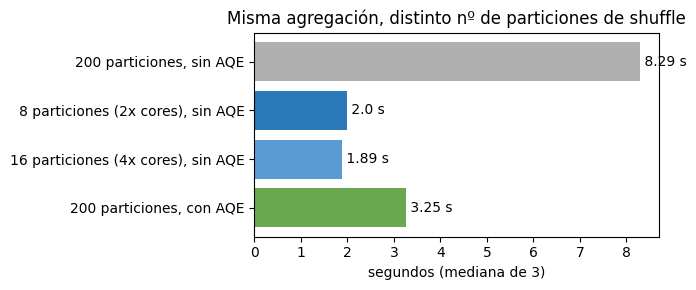

In [25]:
import matplotlib.pyplot as plt
os.makedirs("/opt/workspace/salida_fase2", exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(res_part["configuración"], res_part["tiempo (s)"], color=["#b0b0b0", "#2a7ab9", "#5b9bd5", "#6aa84f"])
for i, v in enumerate(res_part["tiempo (s)"]):
    ax.text(v, i, f" {v} s", va="center")
ax.invert_yaxis(); ax.set_xlabel("segundos (mediana de 3)")
ax.set_title("Misma agregación, distinto nº de particiones de shuffle")
fig.tight_layout(); fig.savefig("/opt/workspace/salida_fase2/grafico_particiones.png", dpi=120)
plt.show()

In [26]:
top = por_entidad.limit(3).toPandas()
mediana_entidad = por_entidad.approxQuantile("count", [0.5], 0)[0]
print(top.to_string(index=False))
print(f"\nMediana de filas por entidad: {mediana_entidad:,.0f}")
print(f"faja_1 / mediana            : {top['count'][0] / mediana_entidad:.0f} a 1")
M.update(faja_pct=float(top["pct"][0]), faja_filas=int(top["count"][0]),
         ratio_faja_mediana=round(top["count"][0] / mediana_entidad))

entidad_id   count   pct
    faja_1 3024000 47.28
 bascula_1  136092  2.13
ambiente_1   50400  0.79

Mediana de filas por entidad: 30,240
faja_1 / mediana            : 100 a 1


In [27]:
spark.conf.set("spark.sql.shuffle.partitions", 32)
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "false")

def diferencia_con_anterior(claves):
    w = Window.partitionBy(*claves).orderBy("timestamp_utc")
    return limpio.withColumn("delta", F.col("valor") - F.lag("valor").over(w))

t_a = ejecutar_en_grupo("ventana_entidad", diferencia_con_anterior(["entidad_id"]))
r_a, tareas_a = resumen_etapa_shuffle("ventana_entidad")
t_b = ejecutar_en_grupo("ventana_entidad_variable", diferencia_con_anterior(["entidad_id", "variable"]))
r_b, tareas_b = resumen_etapa_shuffle("ventana_entidad_variable")

res_skew = pd.DataFrame([
    dict(particion_por="entidad_id", tiempo_s=t_a, **r_a),
    dict(particion_por="entidad_id + variable", tiempo_s=t_b, **r_b),
]).drop(columns="etapa")
print(res_skew.to_string(index=False))
M.update(skew_a=r_a, skew_b=r_b, t_ventana_a=t_a, t_ventana_b=t_b)

        particion_por  tiempo_s  tareas_con_shuffle  mediana_ms  max_ms  ratio_max_mediana  max_filas  mediana_filas
           entidad_id     12.98                  31         483    6232               12.9    3175200         100800
entidad_id + variable     11.21                  32         543    3232                6.0     725760         110880


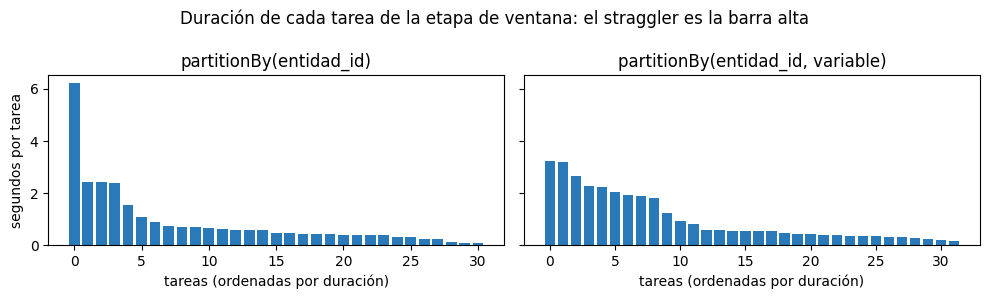

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, (tit, e) in zip(axes, [("partitionBy(entidad_id)", tareas_a),
                               ("partitionBy(entidad_id, variable)", tareas_b)]):
    e = e.sort_values("dur_ms", ascending=False).reset_index(drop=True)
    ax.bar(e.index, e.dur_ms / 1000, color="#2a7ab9")
    ax.set_title(tit); ax.set_xlabel("tareas (ordenadas por duración)")
axes[0].set_ylabel("segundos por tarea")
fig.suptitle("Duración de cada tarea de la etapa de ventana: el straggler es la barra alta")
fig.tight_layout(); fig.savefig("/opt/workspace/salida_fase2/grafico_straggler.png", dpi=120)
plt.show()

In [29]:
N_SAL = 8
dim_activos = (limpio.select("entidad_id", "entidad_tipo").distinct()
                     .withColumn("zona", F.when(F.col("entidad_tipo") == "reefer", "patio")
                                          .otherwise("frente_atraque")))

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)
spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", -1)
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "false")

join_normal = limpio.join(dim_activos.drop("entidad_tipo"), "entidad_id")
t_jn = ejecutar_en_grupo("join_normal", join_normal)
r_jn, _ = resumen_etapa_shuffle("join_normal")

grande_sal = limpio.withColumn("sal", (F.rand(seed=7) * N_SAL).cast("int"))
chica_sal  = dim_activos.drop("entidad_tipo").crossJoin(
    spark.range(N_SAL).select(F.col("id").cast("int").alias("sal")))
join_sal = grande_sal.join(chica_sal, ["entidad_id", "sal"]).drop("sal")
t_js = ejecutar_en_grupo("join_sal", join_sal)
r_js, _ = resumen_etapa_shuffle("join_sal")


spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes", "4MB")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionFactor", "2")
spark.conf.set("spark.sql.adaptive.advisoryPartitionSizeInBytes", "8MB")   # tamaño de cada trozo
t_ja = ejecutar_en_grupo("join_aqe", limpio.join(dim_activos.drop("entidad_tipo"), "entidad_id"))
r_ja, _ = resumen_etapa_shuffle("join_aqe")

assert join_normal.count() == join_sal.count() == n_limpio

for k in ["spark.sql.autoBroadcastJoinThreshold", "spark.sql.adaptive.autoBroadcastJoinThreshold",
          "spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes",
          "spark.sql.adaptive.skewJoin.skewedPartitionFactor",
          "spark.sql.adaptive.advisoryPartitionSizeInBytes", "spark.sql.shuffle.partitions"]:
    spark.conf.unset(k)
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")

res_sal = pd.DataFrame([
    dict(variante="sort-merge normal", tiempo_s=t_jn, **r_jn),
    dict(variante=f"sort-merge con sal (N={N_SAL})", tiempo_s=t_js, **r_js),
    dict(variante="sort-merge + AQE skewJoin", tiempo_s=t_ja, **r_ja),
]).drop(columns="etapa")
print(res_sal.to_string(index=False))
M.update(sal_normal=r_jn, sal_sal=r_js, sal_aqe=r_ja, t_join_normal=t_jn, t_join_sal=t_js, t_join_aqe=t_ja)

                 variante  tiempo_s  tareas_con_shuffle  mediana_ms  max_ms  ratio_max_mediana  max_filas  mediana_filas
        sort-merge normal     14.52                  31         370    4630               12.5    3175206         100804
 sort-merge con sal (N=8)     12.19                  32         365    1146                3.1     523693         111405
sort-merge + AQE skewJoin      8.38                  38         209     653                3.1     413324         120964


In [30]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)
spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", -1)
smj = limpio.join(dim_activos, "entidad_id")
ex_smj = contar_exchanges(smj); t_smj = medir(smj)
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")
spark.conf.unset("spark.sql.adaptive.autoBroadcastJoinThreshold")

bhj = limpio.join(F.broadcast(dim_activos), "entidad_id")
ex_bhj = contar_exchanges(bhj); t_bhj = medir(bhj)

print(pd.DataFrame([["sort-merge join", *ex_smj, t_smj], ["broadcast join", *ex_bhj, t_bhj]],
                   columns=["tipo", "shuffles", "broadcasts", "tiempo (s)"]).to_string(index=False))
print(f"\nBroadcast: {t_smj / t_bhj:.1f}x más rápido; la tabla grande no se movió.")
M.update(t_smj=t_smj, t_bhj=t_bhj, ex_smj=ex_smj[0], ex_bhj=ex_bhj[0])

           tipo  shuffles  broadcasts  tiempo (s)
sort-merge join         3           0        9.85
 broadcast join         1           1        5.23

Broadcast: 1.9x más rápido; la tabla grande no se movió.


In [31]:
rep = limpio.repartition(2)
coa = limpio.coalesce(2)
print(pd.DataFrame([
    ["repartition(2)", contar_exchanges(rep)[0], medir(rep), rep.rdd.getNumPartitions()],
    ["coalesce(2)",    contar_exchanges(coa)[0], medir(coa), coa.rdd.getNumPartitions()],
], columns=["operación", "shuffles", "tiempo (s)", "particiones"]).to_string(index=False))

     operación  shuffles  tiempo (s)  particiones
repartition(2)         1        4.95            2
   coalesce(2)         0        1.37            2


In [32]:
ingenuo = limpio.join(F.broadcast(verdad_limpia),
                      limpio["entidad_id"] == verdad_limpia["entidad_afectada"], "left")
n_ingenuo = ingenuo.count()
print(f"Filas antes del join : {n_limpio:,}")
print(f"Filas después        : {n_ingenuo:,}   <- {n_ingenuo - n_limpio:,} filas fabricadas de la nada")

try:
    assert n_ingenuo == n_limpio, "El join alteró el número de filas"
except AssertionError as e:
    print(f"\nAssertionError atrapado: {e}")

etiq_faja = (ingenuo.filter("entidad_id = 'faja_1' AND falla_id IS NOT NULL")
                    .dropDuplicates(limpio.columns).count())      # lecturas distintas marcadas
total_faja = limpio.filter("entidad_id = 'faja_1'").count()
print(f"Lecturas de faja_1 marcadas como falla: {etiq_faja:,} de {total_faja:,} "
      f"({etiq_faja / total_faja:.0%}) -> ¡incluye los días en que funcionó perfecto!")
M.update(filas_ingenuo=n_ingenuo)

Filas antes del join : 6,395,323
Filas después        : 9,419,323   <- 3,024,000 filas fabricadas de la nada

AssertionError atrapado: El join alteró el número de filas


Lecturas de faja_1 marcadas como falla: 3,024,000 de 3,024,000 (100%) -> ¡incluye los días en que funcionó perfecto!


In [33]:
v = verdad_limpia.select("falla_id", "tipo_falla", "entidad_afectada", "alimentador_afectado",
                         "t_inicio", "t_fin", "severidad")
t = limpio
cond = (
    ((t["entidad_id"] == v["entidad_afectada"]) |
     (v["alimentador_afectado"].isNotNull() & (t["alimentador_id"] == v["alimentador_afectado"])))
    & (t["timestamp_utc"] >= v["t_inicio"])
    & (t["timestamp_utc"] < v["t_fin"])          # t_fin excluido, como en el simulador
)
etiquetada = (t.join(F.broadcast(v), cond, "left")
               .drop("entidad_afectada", "alimentador_afectado", "t_inicio", "t_fin")
               .withColumn("en_falla", F.col("falla_id").isNotNull()))

n_etiquetada = etiquetada.count()
assert n_etiquetada == n_limpio, "El join alteró el número de filas"
print(f"Filas antes: {n_limpio:,} | después: {n_etiquetada:,}  -> la aserción pasa")

print("\nLecturas etiquetadas por falla:")
etiquetada.filter("en_falla").groupBy("falla_id", "tipo_falla").agg(
    F.count("*").alias("lecturas"), F.countDistinct("entidad_id").alias("entidades")
).orderBy("falla_id").show(truncate=False)

etiq_faja_ok = etiquetada.filter("entidad_id = 'faja_1' AND en_falla").count()
print(f"faja_1 en falla: {etiq_faja_ok:,} de {total_faja:,} lecturas ({etiq_faja_ok / total_faja:.0%})")
mostrar_plan(etiquetada)
M.update(filas_etiquetada=n_etiquetada, lecturas_en_falla=etiquetada.filter("en_falla").count(),
         pct_faja_ingenuo=round(etiq_faja / total_faja * 100), pct_faja_correcto=round(etiq_faja_ok / total_faja * 100))

Filas antes: 6,395,323 | después: 6,395,323  -> la aserción pasa

Lecturas etiquetadas por falla:


+--------+--------------------+--------+---------+
|falla_id|tipo_falla          |lecturas|entidades|
+--------+--------------------+--------+---------+
|F001    |compresor_degradado |1983    |1        |
|F002    |puerta_mal_cerrada  |951     |1        |
|F003    |desconexion_equipo  |339     |1        |
|F004    |apertura_alimentador|5621    |26       |
|F006    |rodamiento_faja     |414930  |1        |
|F007    |sobrecarga_faja     |9460    |1        |
|F008    |sensor_pegado       |1113    |1        |
|F009    |deriva_sensor       |1821    |1        |
+--------+--------------------+--------+---------+



faja_1 en falla: 424,390 de 3,024,000 lecturas (14%)
AdaptiveSparkPlan isFinalPlan=false
+- Project [timestamp_utc#556, entidad_id#557, entidad_tipo#558, alimentador_id#955, variable#560, valor#561, unidad#562, calidad_sensor#563, fecha#564, sensor_confiable#956, falla_id#565, tipo_falla#566, severidad#573, isnotnull(falla_id#565) AS en_falla#18348]
   +- BroadcastNestedLoopJoin BuildRight, LeftOuter, ((((entidad_id#557 = entidad_afectada#567) OR (isnotnull(alimentador_afectado#957) AND (alimentador_id#955 = alimentador_afectado#957))) AND (timestamp_utc#556 >= t_inicio#569)) AND (timestamp_utc#556 < t_fin#570))
      :- InMemoryTableScan [timestamp_utc#556, entidad_id#557, entidad_tipo#558, alimentador_id#955, variable#560, valor#561, unidad#562, calidad_sensor#563, fecha#564, sensor_confiable#956]
      :     +- InMemoryRelation [timestamp_utc#556, entidad_id#557, entidad_tipo#558, alimentador_id#955, variable#560, valor#561, unidad#562, calidad_sensor#563, fecha#564, sensor_confiabl

In [34]:
SALIDA = "/opt/workspace/salida_fase2/telemetria_limpia.parquet"
n_instantes = limpio.select("timestamp_utc").distinct().count()
print(f"Instantes distintos: {n_instantes:,}  (serían {n_instantes:,} carpetas si se particionara por timestamp)")

t0 = time.perf_counter()
(etiquetada
    .coalesce(1)
    .write.mode("overwrite")
    .partitionBy("fecha")
    .parquet(SALIDA))
print(f"Escritura: {time.perf_counter() - t0:.1f} s")

Instantes distintos: 604,800  (serían 604,800 carpetas si se particionara por timestamp)


Escritura: 45.1 s


In [35]:
releida = spark.read.parquet(SALIDA)

# Verificaciones con aserciones: si algo falla, el notebook se detiene aquí.
assert releida.count() == n_limpio, "El total escrito no coincide"

por_dia_antes   = {r.fecha: r["count"] for r in etiquetada.groupBy("fecha").count().collect()}
por_dia_despues = {r.fecha: r["count"] for r in releida.groupBy("fecha").count().collect()}
assert por_dia_antes == por_dia_despues, "Algún día perdió o ganó filas"

assert releida.filter("en_falla").count() == M["lecturas_en_falla"], "Se perdieron etiquetas"
assert releida.filter("NOT sensor_confiable").count() == M["no_confiables"], "Se perdieron marcas de calidad"
assert set(releida.columns) >= {"timestamp_utc", "entidad_id", "variable", "valor",
                                "sensor_confiable", "falla_id", "en_falla"}

tipos_escritos = {c.name: c.dataType for c in etiquetada.schema if c.name != "fecha"}
tipos_releidos = {c.name: c.dataType for c in releida.schema if c.name != "fecha"}
assert tipos_escritos == tipos_releidos, "El esquema cambió al releer"
# fecha no va dentro del archivo: Spark la reconstruye desde el nombre de la carpeta.
assert isinstance(releida.schema["fecha"].dataType, DateType), "fecha no se releyó como date"

print("Todas las aserciones pasaron.\n")
print(f"{'carpeta':<22}{'archivos':>9}{'MB':>8}{'filas':>12}")
for d in sorted(os.listdir(SALIDA)):
    ruta = os.path.join(SALIDA, d)
    if os.path.isdir(ruta):
        archivos = [f for f in os.listdir(ruta) if f.endswith(".parquet")]
        mb = sum(os.path.getsize(os.path.join(ruta, f)) for f in archivos) / 1024**2
        fecha = d.split("=")[1]
        print(f"{d:<22}{len(archivos):>9}{mb:>8.1f}{por_dia_despues[pd.Timestamp(fecha).date()]:>12,}")
releida.printSchema()

Todas las aserciones pasaron.

carpeta                archivos      MB       filas
fecha=2026-01-12              1     7.8     926,093
fecha=2026-01-13              1     9.1     942,156
fecha=2026-01-14              1     6.5     897,027
fecha=2026-01-15              1     8.6     942,992
fecha=2026-01-16              1     7.4     912,973
fecha=2026-01-17              1     5.8     887,040
fecha=2026-01-18              1     5.8     887,042
root
 |-- timestamp_utc: timestamp (nullable = true)
 |-- entidad_id: string (nullable = true)
 |-- entidad_tipo: string (nullable = true)
 |-- alimentador_id: integer (nullable = true)
 |-- variable: string (nullable = true)
 |-- valor: double (nullable = true)
 |-- unidad: string (nullable = true)
 |-- calidad_sensor: string (nullable = true)
 |-- sensor_confiable: boolean (nullable = true)
 |-- falla_id: string (nullable = true)
 |-- tipo_falla: string (nullable = true)
 |-- severidad: string (nullable = true)
 |-- en_falla: boolean (nullable =

In [36]:
def fmt(d): return {k: (v if not isinstance(v, dict) else {kk: vv for kk, vv in v.items() if kk != "etapa"}) for k, v in d.items()}
with open("/opt/workspace/salida_fase2/metricas.json", "w") as f:
    json.dump(fmt(M), f, indent=2, default=str)

resumen = [
    ("Registros crudos (JSONL)", f"{M['raw_registros']:,}"),
    ("Transformaciones vs acción", f"{M['t_lazy_transf']} s vs {M['t_lazy_accion']} s"),
    ("Esquema inferido vs declarado", f"{M['t_inferido']} s vs {M['t_declarado']} s"),
    ("JSON vs Parquet (tamaño)", f"{M['mb_json']:,} MB vs {M['mb_parquet']:,} MB"),
    ("Filas del simulador / tras limpieza", f"{M['tele_filas']:,} / {M['limpio_filas']:,}"),
    ("Lecturas marcadas no confiables", f"{M['no_confiables']:,}"),
    ("200 part. / 2x / 4x cores / AQE", f"{M['t_200']} s / {M['t_8']} s / {M['t_16']} s / {M['t_aqe']} s"),
    ("faja_1 del total", f"{M['faja_pct']} %  ({M['ratio_faja_mediana']}:1 vs la mediana)"),
    ("Straggler ventana (máx/mediana)", f"{M['skew_a']['ratio_max_mediana']}x -> {M['skew_b']['ratio_max_mediana']}x con clave fina"),
    ("Sort-merge vs broadcast", f"{M['t_smj']} s vs {M['t_bhj']} s"),
    ("Join ingenuo (filas)", f"{M['limpio_filas']:,} -> {M['filas_ingenuo']:,}"),
    ("Range join (filas)", f"{M['limpio_filas']:,} -> {M['filas_etiquetada']:,}"),
    ("Lecturas etiquetadas en falla", f"{M['lecturas_en_falla']:,}"),
]
print(pd.DataFrame(resumen, columns=["medición", "resultado"]).to_string(index=False))

                           medición                        resultado
           Registros crudos (JSONL)                       10,000,014
         Transformaciones vs acción               0.126 s vs 16.87 s
      Esquema inferido vs declarado               63.02 s vs 15.92 s
           JSON vs Parquet (tamaño)                1,791 MB vs 22 MB
Filas del simulador / tras limpieza            6,395,325 / 6,395,323
    Lecturas marcadas no confiables                          124,219
    200 part. / 2x / 4x cores / AQE 8.29 s / 2.0 s / 1.89 s / 3.25 s
                   faja_1 del total   47.28 %  (100:1 vs la mediana)
    Straggler ventana (máx/mediana)     12.9x -> 6.0x con clave fina
            Sort-merge vs broadcast                 9.85 s vs 5.23 s
               Join ingenuo (filas)           6,395,323 -> 9,419,323
                 Range join (filas)           6,395,323 -> 6,395,323
      Lecturas etiquetadas en falla                          436,218


In [37]:
spark.stop()